# Krylov v3 — Phase 1 Experiment (N=500, P=50) — Pregenerated Data

**Data:** `fix_n500_p50_linear_only` shards (pregenerated, not inline).

**Goal:** Verify the model solves P=50 with shard-loaded data, matching Phase 1 results (corr ≥ 0.993).

**Notebook structure:**
0. Setup & data loading
1. sklearn reference
2. Model setup (from scratch or warm-start)
3. Training (step-based, AMP)
4. Training curves
5. Frozen paired evaluation
6. λ-path comparison
7. Coefficient paths
8. Krylov diagnostics
9. β-scatter
10. Task × ratio heatmaps
11. Timing
12. Summary


In [ ]:
import json
from pathlib import Path
manifest = json.loads(Path("/users/sync_data/generated/fix_n500_p50_linear_only/manifest.json").read_text())
print(json.dumps(manifest, indent=2, default=str)[:2000])

{
  "sync_version": "sync21",
  "num_datasets": 110000,
  "num_datasets_written_this_run": 110000,
  "existing_num_datasets_before_run": 0,
  "shape_mode": "fixed",
  "shard_size": 128,
  "compress": true,
  "num_shards": 860,
  "files": [
    {
      "bucket_id": "n500_p50",
      "path": "shape_n500_p50/shard_0000.npz",
      "num_tasks": 128,
      "n": 500,
      "p": 50
    },
    {
      "bucket_id": "n500_p50",
      "path": "shape_n500_p50/shard_0001.npz",
      "num_tasks": 128,
      "n": 500,
      "p": 50
    },
    {
      "bucket_id": "n500_p50",
      "path": "shape_n500_p50/shard_0002.npz",
      "num_tasks": 128,
      "n": 500,
      "p": 50
    },
    {
      "bucket_id": "n500_p50",
      "path": "shape_n500_p50/shard_0003.npz",
      "num_tasks": 128,
      "n": 500,
      "p": 50
    },
    {
      "bucket_id": "n500_p50",
      "path": "shape_n500_p50/shard_0004.npz",
      "num_tasks": 128,
      "n": 500,
      "p": 50
    },
    {
      "bucket_id": "n500_p50"

## 0. Setup

In [5]:
import os, sys, json, time, math, random, gc
import importlib, importlib.util
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import matplotlib
from pathlib import Path
from collections import defaultdict
from dataclasses import asdict
from sklearn.linear_model import Lasso

matplotlib.rcParams.update({"font.size": 11, "figure.dpi": 120, "figure.figsize": (10, 4)})

WORK_DIR   = Path("/users/junhyeok")
SHARD_DIR  = Path("/users/sync_data/generated/fix_n500_p50_linear_only")
CKPT_DIR   = WORK_DIR / "ckpt_krylov_v3_p50_fix"
FIG_DIR    = CKPT_DIR / "figs"
CKPT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(WORK_DIR))

# ── Robust model import ──
from model_krylov_v3 import (
    KrylovQueryDecoderConfig, KrylovRowSpaceQueryDecoder,
    compute_lambda_pair, lasso_training_loss_v2,
    lasso_objective_per_query, lasso_kkt_topk_per_query,
    center_xy,
)

# ── Robust trainer import (handles renames like train_krylov_v3_gpu.py) ──
def _import_trainer(work_dir: Path):
    required = ('TrainConfig', 'get_lr', 'FIXED_EVAL_RATIOS', 'LOW_LAMBDA_SELECT_WEIGHTS')
    for mod_name in ('train_krylov_v3_gpu', 'train_krylov_v3', 'train_krylov_v3_fast'):
        try:
            mod = importlib.import_module(mod_name)
            if all(hasattr(mod, r) for r in required):
                print(f"Trainer: imported '{mod_name}'")
                return mod
        except ModuleNotFoundError:
            pass
    for path in sorted(work_dir.glob("train_krylov_v3*.py")):
        mod_name = f"_trainer_runtime_{path.stem.replace('-', '_')}"
        try:
            spec = importlib.util.spec_from_file_location(mod_name, path)
            if spec is None or spec.loader is None: continue
            mod = importlib.util.module_from_spec(spec)
            sys.modules[mod_name] = mod
            spec.loader.exec_module(mod)
            if all(hasattr(mod, r) for r in required):
                print(f"Trainer: loaded '{path.name}' via file path")
                return mod
        except Exception as e:
            print(f"  Trainer: skipped {path.name}: {e}")
    raise ImportError("Could not find a compatible trainer module (train_krylov_v3*.py) in " + str(work_dir))

_trainer = _import_trainer(WORK_DIR)
TrainConfig = _trainer.TrainConfig
get_lr = _trainer.get_lr
FIXED_EVAL_RATIOS = _trainer.FIXED_EVAL_RATIOS
LOW_LAMBDA_SELECT_WEIGHTS = _trainer.LOW_LAMBDA_SELECT_WEIGHTS

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
if torch.cuda.is_available():
    print(f"  GPU: {torch.cuda.get_device_name(0)}")
    print(f"  VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
torch.manual_seed(42); random.seed(42); np.random.seed(42)

assert SHARD_DIR.exists(), f"Data not found: {SHARD_DIR}"
manifest = json.loads((SHARD_DIR / "manifest.json").read_text())
# N, P are per-file in this manifest format
N = manifest["files"][0]["n"]
P = manifest["files"][0]["p"]
n_tasks = manifest.get("num_datasets") or sum(f.get("num_tasks", 0) for f in manifest["files"])
print(f"\nData: N={N}, P={P}, tasks={n_tasks}, shards={len(manifest['files'])}")
print(f"  Checkpoints → {CKPT_DIR}")


Trainer: imported 'train_krylov_v3_gpu'
Device: cuda:0
  GPU: NVIDIA GeForce RTX 5070 Ti
  VRAM: 16.6 GB

Data: N=500, P=50, tasks=110000, shards=860
  Checkpoints → /users/junhyeok/ckpt_krylov_v3_p50_fix


## 0b. Shard Loader & Eval Data

In [6]:
class ShardLoader:
    """Load shards to CPU, move only the batch to GPU."""
    def __init__(self, shard_dir, manifest, device="cpu", dtype=torch.float32):
        self.shard_dir = Path(shard_dir)
        self.files = [f["path"] for f in manifest["files"]]
        self.device, self.dtype = device, dtype
        self._shard_order = list(range(len(self.files)))
        random.shuffle(self._shard_order)
        self._shard_ptr = 0

    def load_shard(self, idx, to_device=False):
        d = np.load(self.shard_dir / self.files[idx])
        X = torch.from_numpy(d["X"].astype(np.float32))
        y = torch.from_numpy(d["y"].astype(np.float32))
        if to_device:
            X = X.to(device=self.device, dtype=self.dtype)
            y = y.to(device=self.device, dtype=self.dtype)
        return X, y

    def random_batch(self, batch_size):
        sid = self._shard_order[self._shard_ptr]
        self._shard_ptr += 1
        if self._shard_ptr >= len(self._shard_order):
            random.shuffle(self._shard_order)
            self._shard_ptr = 0
        X, y = self.load_shard(sid, to_device=False)
        if batch_size < X.shape[0]:
            idx = torch.randperm(X.shape[0])[:batch_size]
            X, y = X[idx], y[idx]
        return X.to(device=self.device, dtype=self.dtype), y.to(device=self.device, dtype=self.dtype)

loader = ShardLoader(SHARD_DIR, manifest, device=device)
print(f"Loader: {len(loader.files)} shards, batch→{device} (round-robin)")

# Fixed eval data — at P=50 we can afford more tasks
N_EVAL = 64
_X0, _y0 = loader.load_shard(0, to_device=False)
n_avail = _X0.shape[0]
if N_EVAL > n_avail:
    # Load from multiple shards if needed
    _Xs, _ys = [_X0], [_y0]
    for si in range(1, len(loader.files)):
        if sum(x.shape[0] for x in _Xs) >= N_EVAL: break
        _Xk, _yk = loader.load_shard(si, to_device=False)
        _Xs.append(_Xk); _ys.append(_yk)
    _X0 = torch.cat(_Xs, dim=0); _y0 = torch.cat(_ys, dim=0)
    del _Xs, _ys
X_eval = _X0[:N_EVAL].clone().to(device=device)
y_eval = _y0[:N_EVAL].clone().to(device=device)
del _X0, _y0
X_np_eval = X_eval.cpu().numpy().astype(np.float64)
y_np_eval = y_eval.cpu().numpy().astype(np.float64)
print(f"Eval: {N_EVAL} tasks on {device}, VRAM≈{X_eval.nelement()*4/1e6:.1f} MB")

with torch.no_grad():
    _, lmax_eval = compute_lambda_pair(X_eval, y_eval, ratio_range=(0.005, 0.9))

# EVAL_RATIOS: descending to align with LOW_LAMBDA_SELECT_WEIGHTS
EVAL_RATIOS = [0.9, 0.5, 0.2, 0.1, 0.05, 0.02, 0.01, 0.005]
print(f"EVAL_RATIOS (descending): {EVAL_RATIOS}")


Loader: 860 shards, batch→cuda:0 (round-robin)
Eval: 64 tasks on cuda:0, VRAM≈6.4 MB
EVAL_RATIOS (descending): [0.9, 0.5, 0.2, 0.1, 0.05, 0.02, 0.01, 0.005]


## 1. sklearn Reference at P=50

At P=50 sklearn is fast — run on all eval tasks.

In [7]:
N_SK = N_EVAL  # P=50 is cheap, use all eval tasks

def sklearn_solve(Xb, yb, ratio, max_iter=20000, tol=1e-6):
    Xc = Xb - Xb.mean(0, keepdims=True)
    yc = yb - yb.mean()
    lm = np.abs(Xc.T @ yc / len(yb)).max()
    alpha = ratio * lm
    clf = Lasso(alpha=alpha, fit_intercept=True, max_iter=max_iter, tol=tol)
    clf.fit(Xb, yb)
    res = yb - Xb @ clf.coef_ - clf.intercept_
    obj = 0.5 * np.mean(res**2) + alpha * np.abs(clf.coef_).sum()
    nnz = np.sum(np.abs(clf.coef_) > 1e-4)
    return obj, clf.coef_.copy(), clf.intercept_, nnz

print(f"sklearn: {N_SK} tasks x {len(EVAL_RATIOS)} ratios at P={P}")
print(f"{'ratio':>8s}  {'obj':>10s}  {'nnz':>6s}  {'time':>7s}")
print("-" * 38)

sklearn_ref = {}
sklearn_betas = {}

for r in EVAL_RATIOS:
    objs, betas, nnzs = [], [], []
    t0 = time.perf_counter()
    for b in range(N_SK):
        obj, coef, _, nnz = sklearn_solve(X_np_eval[b], y_np_eval[b], r)
        objs.append(obj); betas.append(coef); nnzs.append(nnz)
    dt = time.perf_counter() - t0
    sklearn_ref[r] = {"obj_mean": np.mean(objs), "nnz_mean": np.mean(nnzs), "time_s": dt}
    sklearn_betas[r] = np.stack(betas)
    print(f"{r:>8.3f}  {np.mean(objs):>10.4f}  {np.mean(nnzs):>6.1f}  {dt:>6.2f}s")

print(f"\nsklearn total: {sum(v['time_s'] for v in sklearn_ref.values()):.1f}s")


sklearn: 64 tasks x 8 ratios at P=50
   ratio         obj     nnz     time
--------------------------------------
   0.900      0.5018     1.5    0.02s
   0.500      0.4707     5.2    0.02s
   0.200      0.3869    13.5    0.03s
   0.100      0.3330    20.0    0.04s
   0.050      0.2959    27.4    0.04s
   0.020      0.2670    36.5    0.05s
   0.010      0.2549    41.7    0.05s
   0.005      0.2479    45.4    0.07s

sklearn total: 0.3s


## 2. Model Setup & Warm-Start

In [8]:
# ── Desired model config (87,976 params with bilinear) ──
desired_cfg = KrylovQueryDecoderConfig(
    krylov_dim=16, num_decoder_channels=12, use_bilinear_channels=True,
    cond_dim=32, cond_hidden=96, query_mixer_hidden=96,
    feature_head_hidden=160, prox_hidden=80,
    use_krylov_ridge_base=True, base_head_hidden=64,
    retain_U=False, retain_centered_data_in_encoding=False,
)

# ── Warm-start from existing P=50 checkpoint if available ──
P50_CKPT = WORK_DIR / "ckpt_krylov_v3" / "best.pt"

if P50_CKPT.exists():
    ckpt = torch.load(P50_CKPT, map_location=device, weights_only=False)
    ckpt_model_cfg = ckpt.get("model_cfg", None)
    if ckpt_model_cfg is not None:
        valid_fields = {f.name for f in KrylovQueryDecoderConfig.__dataclass_fields__.values()}
        filtered = {k: v for k, v in ckpt_model_cfg.items() if k in valid_fields}
        model_cfg = KrylovQueryDecoderConfig(**filtered)
        model_cfg.retain_U = False
        model_cfg.retain_centered_data_in_encoding = False
        print(f"Config from checkpoint: krylov_dim={model_cfg.krylov_dim}, "
              f"channels={model_cfg.num_decoder_channels}, bilinear={getattr(model_cfg, 'use_bilinear_channels', False)}")
    else:
        model_cfg = desired_cfg
        print("No model_cfg in checkpoint, using desired config")
    model = KrylovRowSpaceQueryDecoder(model_cfg).to(device)
    try:
        model.load_state_dict(ckpt["model_state"], strict=True)
        print(f"Warm-started (strict): {P50_CKPT.name}")
    except RuntimeError as e:
        print(f"Strict load failed, trying partial: {str(e)[:100]}...")
        info = model.load_state_dict(ckpt["model_state"], strict=False)
        print(f"  Loaded with {len(info.missing_keys)} missing, {len(info.unexpected_keys)} unexpected keys")
    del ckpt
else:
    model_cfg = desired_cfg
    model = KrylovRowSpaceQueryDecoder(model_cfg).to(device)
    print("No checkpoint found — training from scratch")

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nModel: {n_params:,} params")
print(f"  krylov_dim={model_cfg.krylov_dim}, channels={model_cfg.num_decoder_channels}, "
      f"cond_dim={model_cfg.cond_dim}, bilinear={getattr(model_cfg, 'use_bilinear_channels', False)}")

with torch.no_grad():
    lam_test = lmax_eval[:2, None] * torch.tensor([0.1], device=device)
    b_test = model(X_eval[:2], y_eval[:2], lambdas=lam_test)
    print(f"Forward OK: {tuple(b_test.shape)}, finite={torch.isfinite(b_test).all().item()}")
    del b_test


Config from checkpoint: krylov_dim=16, channels=12, bilinear=True
Warm-started (strict): best.pt

Model: 87,976 params
  krylov_dim=16, channels=12, cond_dim=32, bilinear=True
Forward OK: (2, 50), finite=True


In [10]:
# ── Training config ──
TOTAL_STEPS = 10_000
BATCH_SIZE  = 64        # P=50 is light — can use large batch
NUM_LAMBDAS = 8
EVAL_EVERY  = 500
LOG_EVERY   = 100
KKT_WEIGHT  = 0.5
KKT_INACTIVE_TOPK = 256  # P=50 → 256 is fine

_tcfg_kwargs = dict(
    N=N, P=P, total_steps=TOTAL_STEPS, batch_size=BATCH_SIZE,
    lr=3e-4, warmup_steps=200, num_lambdas=NUM_LAMBDAS,
    eval_every=EVAL_EVERY, log_every=LOG_EVERY, eval_tasks=N_EVAL,
    krylov_dim=model_cfg.krylov_dim,
    num_decoder_channels=model_cfg.num_decoder_channels,
    cond_dim=model_cfg.cond_dim,
    cond_hidden=model_cfg.cond_hidden,
    query_mixer_hidden=model_cfg.query_mixer_hidden,
    feature_head_hidden=model_cfg.feature_head_hidden,
    prox_hidden=model_cfg.prox_hidden,
    use_progressive=False,
)
if hasattr(TrainConfig, 'use_bilinear_channels'):
    _tcfg_kwargs['use_bilinear_channels'] = getattr(model_cfg, 'use_bilinear_channels', False)
train_cfg = TrainConfig(**_tcfg_kwargs)

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4, betas=(0.9, 0.98))
history = {"step": [], "loss": [], "eval_select": [], "eval_obj_r001": [],
           "eval_kkt_r001": []}
best_score = float("inf")
running_loss, running_count = 0.0, 0

# ── Precision ──
if device.type == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    try: torch.set_float32_matmul_precision("high")
    except Exception: pass
amp_enabled = device.type == "cuda" and torch.cuda.is_bf16_supported()
amp_dtype = torch.bfloat16
print(f"Mixed precision: {'bf16+TF32' if amp_enabled else 'TF32 only' if device.type == 'cuda' else 'OFF'}")

print(f"{'='*65}")
print(f"Training: P={P}, {TOTAL_STEPS} steps, batch={BATCH_SIZE}, Q={NUM_LAMBDAS}")
print(f"{'='*65}\n")

model.train(); t0 = time.time()

for step in range(1, TOTAL_STEPS + 1):
    lr_now = get_lr(step, train_cfg)
    for pg in optimizer.param_groups: pg["lr"] = lr_now
    optimizer.zero_grad(set_to_none=True)

    X, y = loader.random_batch(BATCH_SIZE)
    B = X.shape[0]  # may be < BATCH_SIZE for short shards
    with torch.no_grad():
        _, lam_max = compute_lambda_pair(X, y, ratio_range=(5e-3, 0.9))
        u = torch.rand(B, NUM_LAMBDAS, device=device)
        lambdas = torch.exp(torch.log(lam_max*5e-3)[:, None]
                            + u * (torch.log(lam_max*0.9) - torch.log(lam_max*5e-3))[:, None])
        lambdas, _ = lambdas.sort(dim=1, descending=True)

    with torch.autocast(device_type="cuda", dtype=amp_dtype, enabled=amp_enabled):
        pre = model.precompute(X, y); enc = model.encode_dataset(pre)
        beta = model.solve_queries(enc, lambdas=lambdas)
        loss = lasso_training_loss_v2(X, y, beta, lambdas, lambda_max=enc["lambda_max"],
                                       precomputed={"Xc": pre["Xc"], "yc": pre["yc"]},
                                       kkt_weight=KKT_WEIGHT,
                                       kkt_inactive_topk=KKT_INACTIVE_TOPK)
        del pre, enc, beta
    loss.backward()

    gn = nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()
    running_loss += loss.item(); running_count += 1
    del X, y, lambdas, loss

    if step % LOG_EVERY == 0 or step == 1:
        avg = running_loss / max(running_count, 1)
        mem = f" vram={torch.cuda.max_memory_allocated()/1e9:.1f}G" if device.type == "cuda" else ""
        print(f"  [{step:>6d}] loss={avg:.4f} |g|={gn:.2f} lr={lr_now:.1e}"
              f" {running_count/(time.time()-t0):.1f}it/s{mem}")
        running_loss = running_count = 0; t0 = time.time()

    if step % EVAL_EVERY == 0 or step == 1 or step == TOTAL_STEPS:
        model.eval()
        with torch.no_grad():
            rt = torch.tensor(EVAL_RATIOS, device=device)
            lam_e = lmax_eval[:, None] * rt[None, :]
            with torch.autocast(device_type="cuda", dtype=amp_dtype, enabled=amp_enabled):
                bh = model(X_eval, y_eval, lambdas=lam_e)
            Xc, yc, _, _ = center_xy(X_eval, y_eval)
            oq = lasso_objective_per_query(X_eval, y_eval, bh, lam_e, precomputed={"Xc": Xc, "yc": yc})
            kq = lasso_kkt_topk_per_query(X_eval, y_eval, bh, lam_e, precomputed={"Xc": Xc, "yc": yc})
            w = LOW_LAMBDA_SELECT_WEIGHTS.to(device)[:len(EVAL_RATIOS)]
            sel = ((oq.mean(0) * w).sum() / w.sum()).item()
            i01 = EVAL_RATIOS.index(0.01)
            o01, k01 = oq[:, i01].mean().item(), kq[:, i01].mean().item()
            nz01 = (bh[:, i01].abs() > 1e-4).float().sum(-1).mean().item()
        last_avg = running_loss / max(running_count, 1) if running_count > 0 else 0
        history["step"].append(step); history["loss"].append(last_avg)
        history["eval_select"].append(sel); history["eval_obj_r001"].append(o01)
        history["eval_kkt_r001"].append(k01)
        if sel < best_score:
            best_score = sel
            torch.save({"step": step, "model_state": model.state_dict(),
                         "model_cfg": asdict(model_cfg)}, CKPT_DIR / "best.pt")
        star = "★" if sel <= best_score else " "
        print(f"  EVAL [{step}] sel={sel:.3f} obj@.01={o01:.4f} kkt={k01:.4f} nnz={nz01:.0f} {star}\n")
        model.train(); del bh, Xc, yc, oq, kq
    if device.type == "cuda" and step % 500 == 0: torch.cuda.empty_cache()

print(f"Done. Best select_score: {best_score:.4f}")


Mixed precision: bf16+TF32
Training: P=50, 10000 steps, batch=64, Q=8

  [     1] loss=0.2650 |g|=0.02 lr=3.0e-06 11.4it/s vram=0.2G
  EVAL [1] sel=0.279 obj@.01=0.2560 kkt=0.0001 nnz=47 ★

  [   100] loss=0.2685 |g|=0.04 lr=1.5e-04 14.6it/s vram=0.2G
  [   200] loss=0.2687 |g|=0.06 lr=3.0e-04 15.1it/s vram=0.2G
  [   300] loss=0.2690 |g|=0.05 lr=3.0e-04 15.0it/s vram=0.2G
  [   400] loss=0.2680 |g|=0.03 lr=3.0e-04 15.2it/s vram=0.2G
  [   500] loss=0.2669 |g|=0.06 lr=3.0e-04 14.9it/s vram=0.2G
  EVAL [500] sel=0.279 obj@.01=0.2559 kkt=0.0001 nnz=47 ★

  [   600] loss=0.2688 |g|=0.05 lr=3.0e-04 15.3it/s vram=0.2G
  [   700] loss=0.2688 |g|=0.02 lr=3.0e-04 16.1it/s vram=0.2G
  [   800] loss=0.2683 |g|=0.02 lr=3.0e-04 15.9it/s vram=0.2G
  [   900] loss=0.2673 |g|=0.03 lr=3.0e-04 15.1it/s vram=0.2G
  [  1000] loss=0.2690 |g|=0.06 lr=3.0e-04 15.1it/s vram=0.2G
  EVAL [1000] sel=0.279 obj@.01=0.2559 kkt=0.0001 nnz=48 ★

  [  1100] loss=0.2691 |g|=0.03 lr=2.9e-04 15.2it/s vram=0.2G
  [  1200

## 3. Training Curves

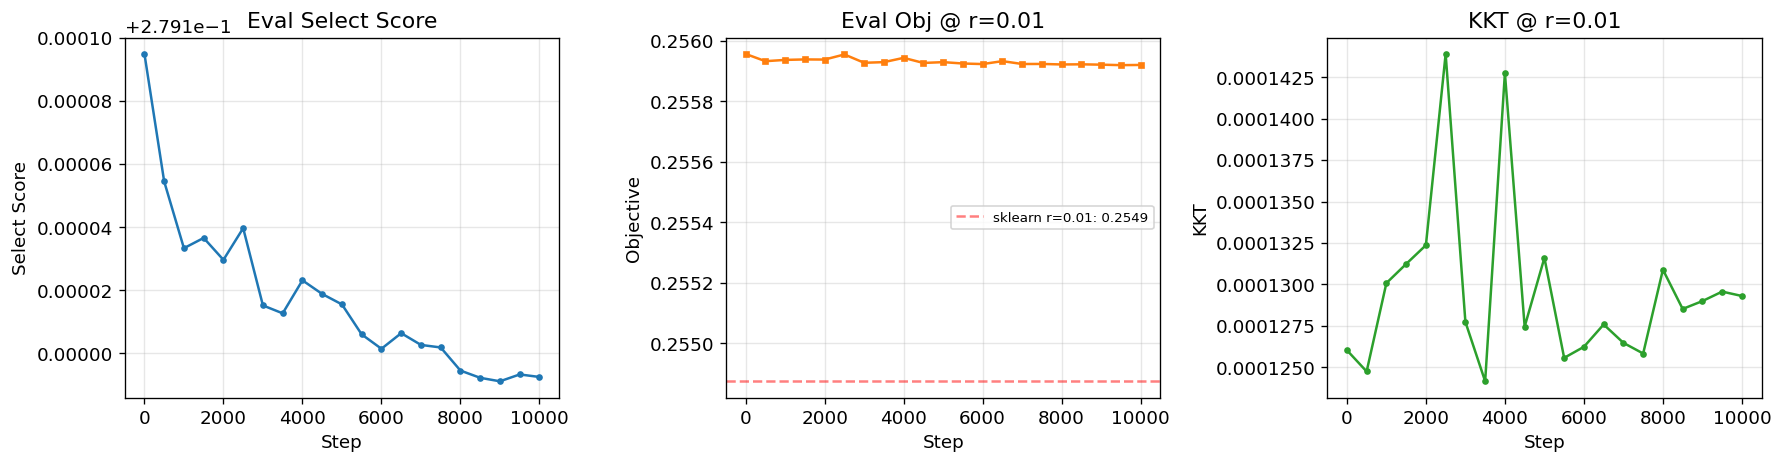

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(history["step"], history["eval_select"], "o-", ms=3)
axes[0].set_xlabel("Step"); axes[0].set_ylabel("Select Score")
axes[0].set_title("Eval Select Score"); axes[0].grid(True, alpha=0.3)

axes[1].plot(history["step"], history["eval_obj_r001"], "s-", ms=3, color="C1")
sk01 = sklearn_ref.get(0.01, {}).get("obj_mean", None)
if sk01: axes[1].axhline(sk01, color="red", ls="--", alpha=0.5, label=f"sklearn r=0.01: {sk01:.4f}")
axes[1].set_xlabel("Step"); axes[1].set_ylabel("Objective")
axes[1].set_title("Eval Obj @ r=0.01"); axes[1].legend(fontsize=8); axes[1].grid(True, alpha=0.3)

axes[2].plot(history["step"], history["eval_kkt_r001"], "o-", ms=3, color="C2")
axes[2].set_xlabel("Step"); axes[2].set_ylabel("KKT"); axes[2].set_title("KKT @ r=0.01")
axes[2].grid(True, alpha=0.3)

plt.tight_layout(); plt.savefig(FIG_DIR/"01_training_curves.png", dpi=150, bbox_inches="tight"); plt.show()


## 4. Frozen Paired Evaluation (apples-to-apples)

**Both model and sklearn on identical `X_eval, y_eval`.** The definitive table.


In [12]:
@torch.no_grad()
def frozen_paired_eval(model, X, y, ratios, X_np, y_np):
    model.eval(); B = X.shape[0]
    _, lam_max = compute_lambda_pair(X, y, ratio_range=(min(ratios), max(ratios)))
    rt = torch.tensor(ratios, device=X.device, dtype=torch.float32)
    lambdas = lam_max[:, None] * rt[None, :]
    with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=amp_enabled):
        beta_hat = model(X, y, lambdas=lambdas)
    Xc, yc, _, _ = center_xy(X, y)
    obj_q = lasso_objective_per_query(X, y, beta_hat, lambdas, precomputed={"Xc": Xc, "yc": yc})
    kkt_q = lasso_kkt_topk_per_query(X, y, beta_hat, lambdas, precomputed={"Xc": Xc, "yc": yc})

    rows = []
    for qi, r in enumerate(ratios):
        objs_sk, betas_sk = [], []
        for b in range(B):
            obj_s, coef_s, _, _ = sklearn_solve(X_np[b], y_np[b], r)
            objs_sk.append(obj_s); betas_sk.append(coef_s)
        betas_sk = np.stack(betas_sk)
        bm = beta_hat[:, qi].cpu().numpy()
        corrs = [np.corrcoef(bm[b], betas_sk[b])[0, 1] if np.std(betas_sk[b]) > 1e-10 else 0 for b in range(B)]
        mses = [np.mean((bm[b] - betas_sk[b])**2) for b in range(B)]
        nnz_m = np.mean((np.abs(bm) > 1e-4).sum(-1))
        nnz_s = np.mean((np.abs(betas_sk) > 1e-4).sum(-1))
        obj_m = obj_q[:, qi].mean().item()
        obj_s = float(np.mean(objs_sk))
        rows.append({"r": r, "obj_model": obj_m, "obj_sklearn": obj_s,
                      "obj_gap": obj_m / obj_s if obj_s > 0 else float("nan"),
                      "kkt": kkt_q[:, qi].mean().item(),
                      "nnz_model": nnz_m, "nnz_sklearn": nnz_s,
                      "beta_corr": float(np.mean(corrs)), "beta_mse": float(np.mean(mses))})
    return pd.DataFrame(rows).set_index("r")

print(f"Frozen paired eval: {N_EVAL} tasks x {len(EVAL_RATIOS)} ratios...")
paired = frozen_paired_eval(model, X_eval, y_eval, EVAL_RATIOS, X_np_eval, y_np_eval)

print("\n" + "=" * 88)
print("FROZEN PAIRED EVALUATION — identical (X, y), apples-to-apples")
print("=" * 88)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
print(paired.to_string())
print("=" * 88)
print(f"\nAvg obj gap:   {paired['obj_gap'].mean():.4f}x")
print(f"Avg beta corr: {paired['beta_corr'].mean():.4f}")


Frozen paired eval: 64 tasks x 8 ratios...

FROZEN PAIRED EVALUATION — identical (X, y), apples-to-apples
        obj_model  obj_sklearn  obj_gap    kkt  nnz_model  nnz_sklearn  beta_corr  beta_mse
r                                                                                          
0.9000     0.5019       0.5018   1.0002 0.0005     1.5469       1.4688     0.9689    0.0000
0.5000     0.4734       0.4707   1.0057 0.0037     6.7500       5.1562     0.9302    0.0002
0.2000     0.3935       0.3869   1.0170 0.0034    20.0312      13.5000     0.9196    0.0006
0.1000     0.3391       0.3330   1.0183 0.0021    30.5469      20.0469     0.9358    0.0007
0.0500     0.3000       0.2959   1.0140 0.0009    38.6719      27.3906     0.9529    0.0007
0.0200     0.2688       0.2670   1.0067 0.0002    45.1875      36.5000     0.9753    0.0005
0.0100     0.2559       0.2549   1.0041 0.0001    47.6406      41.6562     0.9865    0.0004
0.0050     0.2492       0.2479   1.0054 0.0002    48.5781      45.

## 5. Lambda-Path Comparison

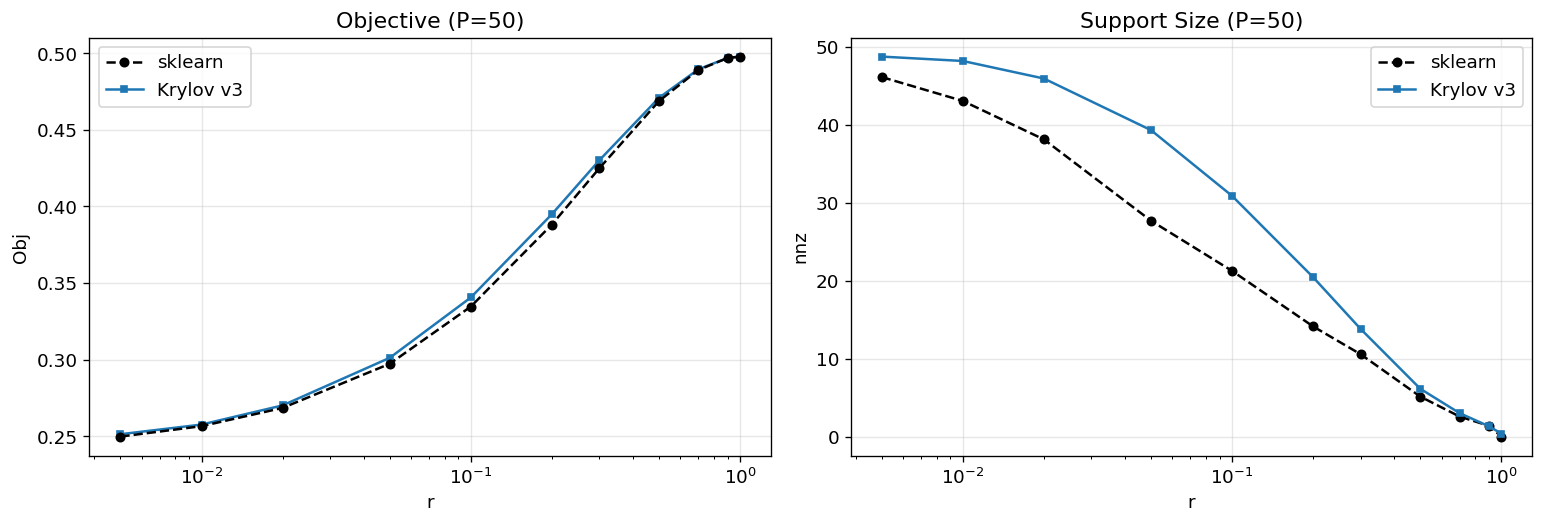

In [13]:
PATH_RATIOS = [0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9, 1.0]
N_PATH = min(16, N_EVAL)

model.eval()
with torch.no_grad():
    _, lm = compute_lambda_pair(X_eval[:N_PATH], y_eval[:N_PATH],
                                 ratio_range=(min(PATH_RATIOS), max(PATH_RATIOS)))
    lam = lm[:, None] * torch.tensor(PATH_RATIOS, device=device)
    t0 = time.perf_counter()
    with torch.autocast(device_type="cuda", dtype=amp_dtype, enabled=amp_enabled):
        bh = model(X_eval[:N_PATH], y_eval[:N_PATH], lambdas=lam)
    if device.type == "cuda": torch.cuda.synchronize()
    t_model = time.perf_counter() - t0
    Xc, yc, _, _ = center_xy(X_eval[:N_PATH], y_eval[:N_PATH])
    obj_m = lasso_objective_per_query(X_eval[:N_PATH], y_eval[:N_PATH], bh, lam,
                                       precomputed={"Xc": Xc, "yc": yc}).mean(0).cpu().numpy()
    nnz_m = (bh.abs() > 1e-4).float().sum(-1).mean(0).cpu().numpy()
del bh, Xc, yc

sk_obj, sk_nnz = [], []
for r in PATH_RATIOS:
    os_, ns_ = [], []
    for b in range(N_PATH):
        o, _, _, n = sklearn_solve(X_np_eval[b], y_np_eval[b], r)
        os_.append(o); ns_.append(n)
    sk_obj.append(np.mean(os_)); sk_nnz.append(np.mean(ns_))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(PATH_RATIOS, sk_obj, "k--o", ms=5, label="sklearn", zorder=5)
axes[0].plot(PATH_RATIOS, obj_m, "C0-s", ms=4, label="Krylov v3")
axes[0].set_xscale("log"); axes[0].set_xlabel("r"); axes[0].set_ylabel("Obj")
axes[0].set_title(f"Objective (P={P})"); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(PATH_RATIOS, sk_nnz, "k--o", ms=5, label="sklearn")
axes[1].plot(PATH_RATIOS, nnz_m, "C0-s", ms=4, label="Krylov v3")
axes[1].set_xscale("log"); axes[1].set_xlabel("r"); axes[1].set_ylabel("nnz")
axes[1].set_title(f"Support Size (P={P})"); axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout(); plt.savefig(FIG_DIR/"02_lambda_path.png", dpi=150, bbox_inches="tight"); plt.show()


## 6. Side-by-Side Coefficient Paths

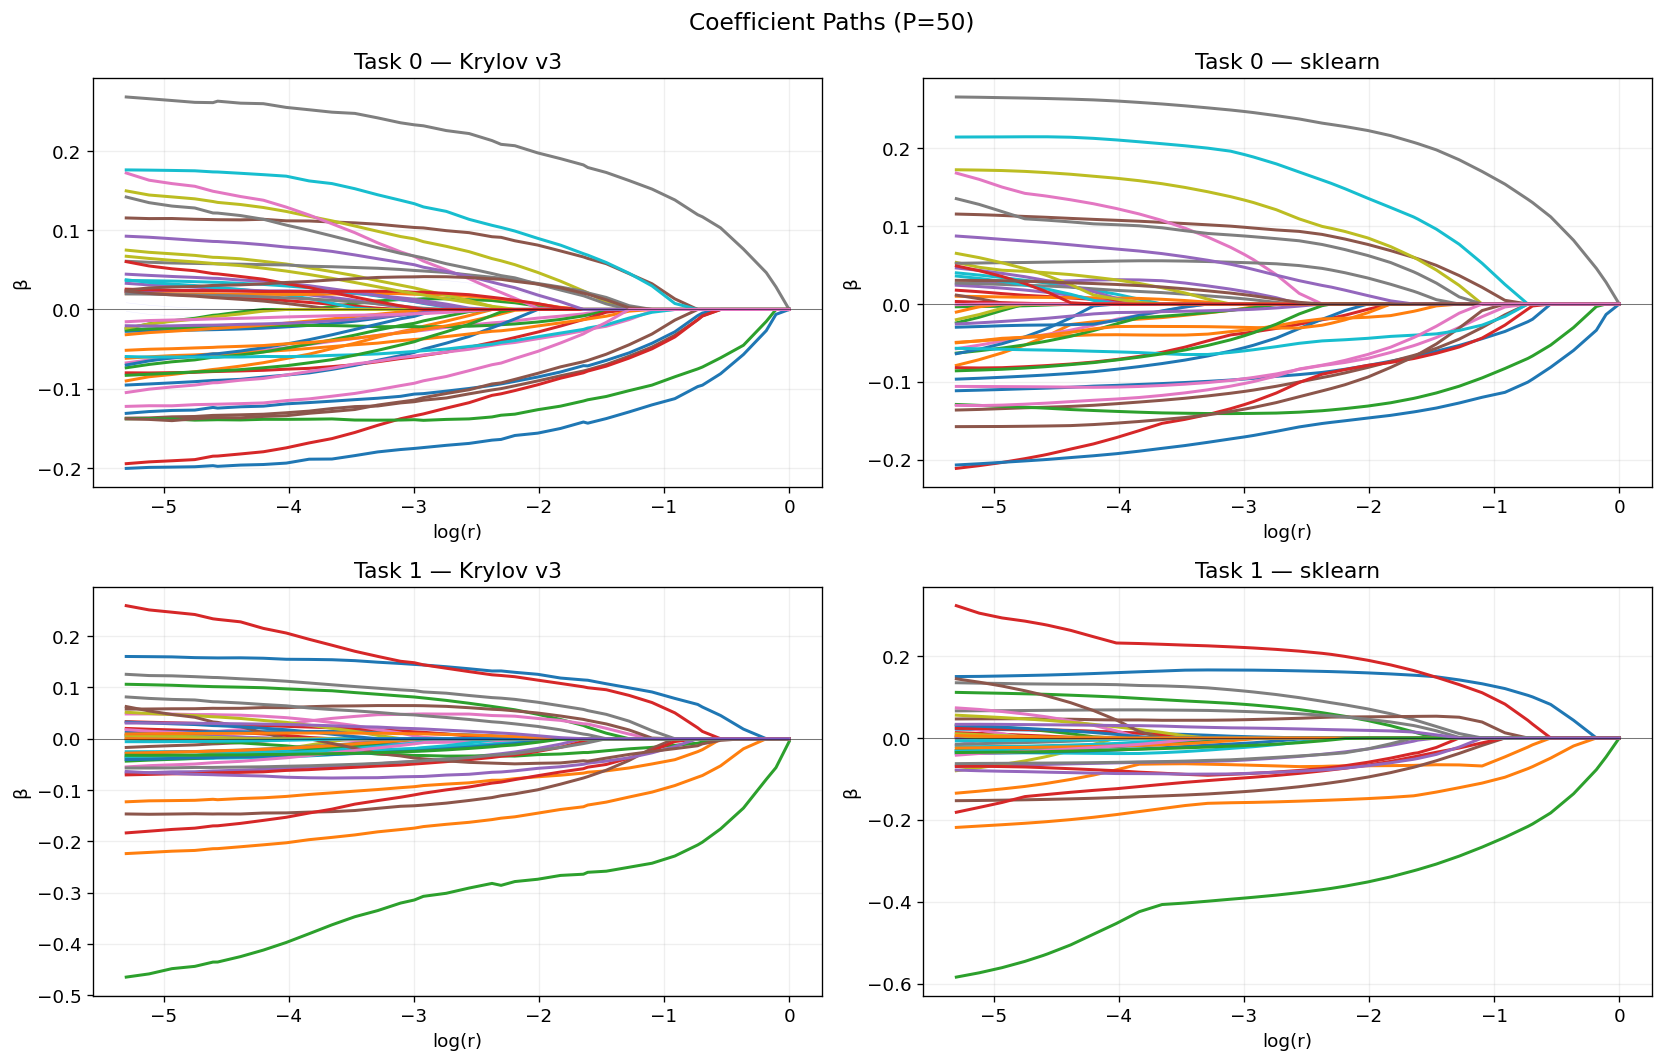

29553

In [14]:
N_TRACE = 2
TRACE_RATIOS = np.sort(np.unique(np.concatenate([
    np.logspace(np.log10(0.005), 0, 30),
    np.array([0.01, 0.05, 0.1, 0.2, 0.5, 0.9, 1.0]),
])))[::-1]

model.eval()
with torch.no_grad():
    _, lmt = compute_lambda_pair(X_eval[:N_TRACE], y_eval[:N_TRACE],
                                  ratio_range=(min(TRACE_RATIOS), max(TRACE_RATIOS)))
    rt = torch.tensor(np.ascontiguousarray(TRACE_RATIOS), device=device, dtype=torch.float32)
    with torch.autocast(device_type="cuda", dtype=amp_dtype, enabled=amp_enabled):
        beta_m = model(X_eval[:N_TRACE], y_eval[:N_TRACE], lambdas=lmt[:, None] * rt[None, :]).cpu().numpy()

beta_s = np.zeros_like(beta_m)
for b in range(N_TRACE):
    for qi, r in enumerate(TRACE_RATIOS):
        _, coef, _, _ = sklearn_solve(X_np_eval[b], y_np_eval[b], r)
        beta_s[b, qi] = coef

log_r = np.log(np.maximum(TRACE_RATIOS, 1e-12))

fig, axes = plt.subplots(N_TRACE, 2, figsize=(14, 4.5 * N_TRACE), squeeze=False)
for i in range(N_TRACE):
    imp = np.where(np.abs(beta_s[i, -1]) > 1e-4)[0]
    if len(imp) == 0: imp = np.argsort(np.abs(beta_s[i, -1]))[-10:]
    for col, (bmat, title) in enumerate([(beta_m[i], "Krylov v3"), (beta_s[i], "sklearn")]):
        ax = axes[i, col]
        for j in imp: ax.plot(log_r, bmat[:, j], lw=1.8)
        noise = np.setdiff1d(np.arange(P), imp)
        for j in noise: ax.plot(log_r, bmat[:, j], color="blue", alpha=0.08, lw=0.3)
        ax.axhline(0, color="k", lw=0.5, alpha=0.6)
        ax.set_xlabel("log(r)"); ax.set_ylabel("β"); ax.set_title(f"Task {i} — {title}")
        ax.grid(True, alpha=0.2)
plt.suptitle(f"Coefficient Paths (P={P})", fontsize=14)
plt.tight_layout(); plt.savefig(FIG_DIR/"03_coeff_paths.png", dpi=150, bbox_inches="tight"); plt.show()
del beta_m, beta_s; gc.collect()


## 7. Krylov & Decoder Diagnostics

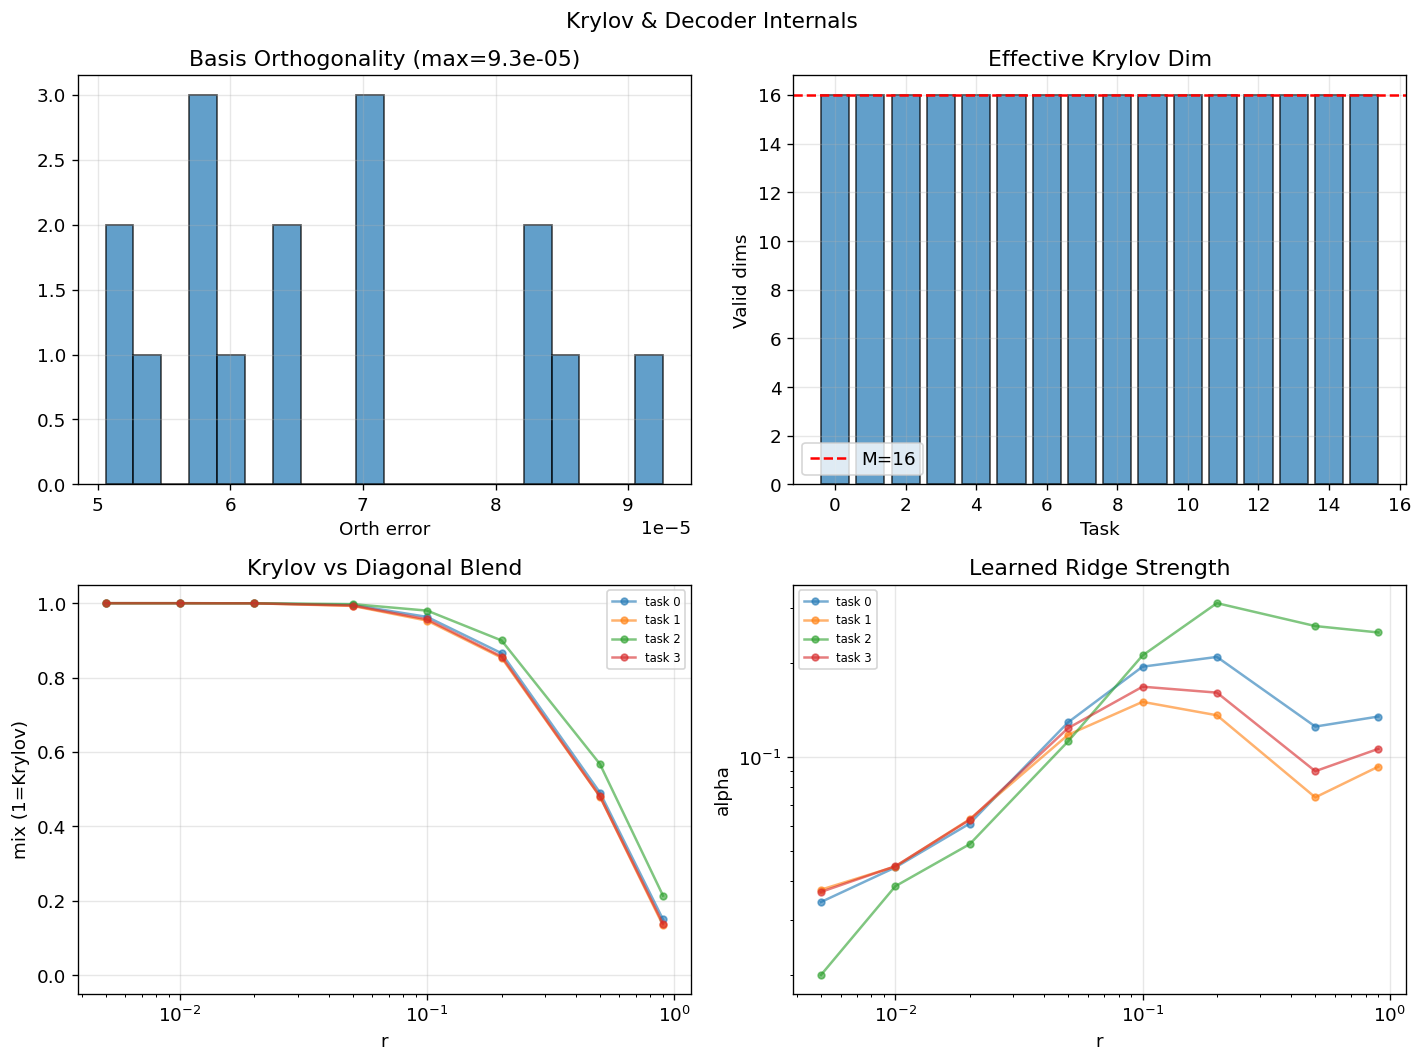

Orth error: max=9.3e-05  Eff dim: [16 16 16 16 16 16 16 16 16 16 16 16 16 16 16 16]
Base mix range: [0.129, 1.000]


2240

In [15]:
N_DIAG = min(16, N_EVAL)
model.eval()
with torch.no_grad():
    _, lmd = compute_lambda_pair(X_eval[:N_DIAG], y_eval[:N_DIAG],
                                  ratio_range=(min(EVAL_RATIOS), max(EVAL_RATIOS)))
    lam_d = lmd[:, None] * torch.tensor(EVAL_RATIOS, device=device)
    pre = model.precompute(X_eval[:N_DIAG], y_eval[:N_DIAG])
    enc = model.encode_dataset(pre)
    out = model.solve_queries(enc, lambdas=lam_d, return_aux=True)

bd = enc["basis_diagnostics"]
orth_err = bd["orthogonality_error"].cpu().numpy()
eff_dim = bd["valid_mask"].cpu().numpy().sum(1)
base_mix = out["base_mix_q"].cpu().numpy()
base_alpha = out["base_alpha_q"].cpu().numpy()

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes[0, 0].hist(orth_err, bins=20, edgecolor="black", alpha=0.7)
axes[0, 0].set_xlabel("Orth error"); axes[0, 0].set_title(f"Basis Orthogonality (max={orth_err.max():.1e})")
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].bar(range(N_DIAG), eff_dim, edgecolor="black", alpha=0.7)
axes[0, 1].axhline(model_cfg.krylov_dim, color="red", ls="--", label=f"M={model_cfg.krylov_dim}")
axes[0, 1].set_xlabel("Task"); axes[0, 1].set_ylabel("Valid dims"); axes[0, 1].set_title("Effective Krylov Dim")
axes[0, 1].legend(); axes[0, 1].grid(True, alpha=0.3)

ra = np.array(EVAL_RATIOS)
for b in range(min(4, N_DIAG)):
    axes[1, 0].plot(ra, base_mix[b], "o-", ms=4, alpha=0.6, label=f"task {b}")
axes[1, 0].set_xscale("log"); axes[1, 0].set_ylim(-0.05, 1.05)
axes[1, 0].set_xlabel("r"); axes[1, 0].set_ylabel("mix (1=Krylov)")
axes[1, 0].set_title("Krylov vs Diagonal Blend"); axes[1, 0].legend(fontsize=7); axes[1, 0].grid(True, alpha=0.3)

for b in range(min(4, N_DIAG)):
    axes[1, 1].plot(ra, base_alpha[b], "o-", ms=4, alpha=0.6, label=f"task {b}")
axes[1, 1].set_xscale("log"); axes[1, 1].set_yscale("log")
axes[1, 1].set_xlabel("r"); axes[1, 1].set_ylabel("alpha")
axes[1, 1].set_title("Learned Ridge Strength"); axes[1, 1].legend(fontsize=7); axes[1, 1].grid(True, alpha=0.3)

plt.suptitle("Krylov & Decoder Internals", fontsize=13)
plt.tight_layout(); plt.savefig(FIG_DIR/"04_krylov_diag.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"Orth error: max={orth_err.max():.1e}  Eff dim: {eff_dim}")
print(f"Base mix range: [{base_mix.min():.3f}, {base_mix.max():.3f}]")
del pre, enc, out; gc.collect()


## 8. Beta Scatter

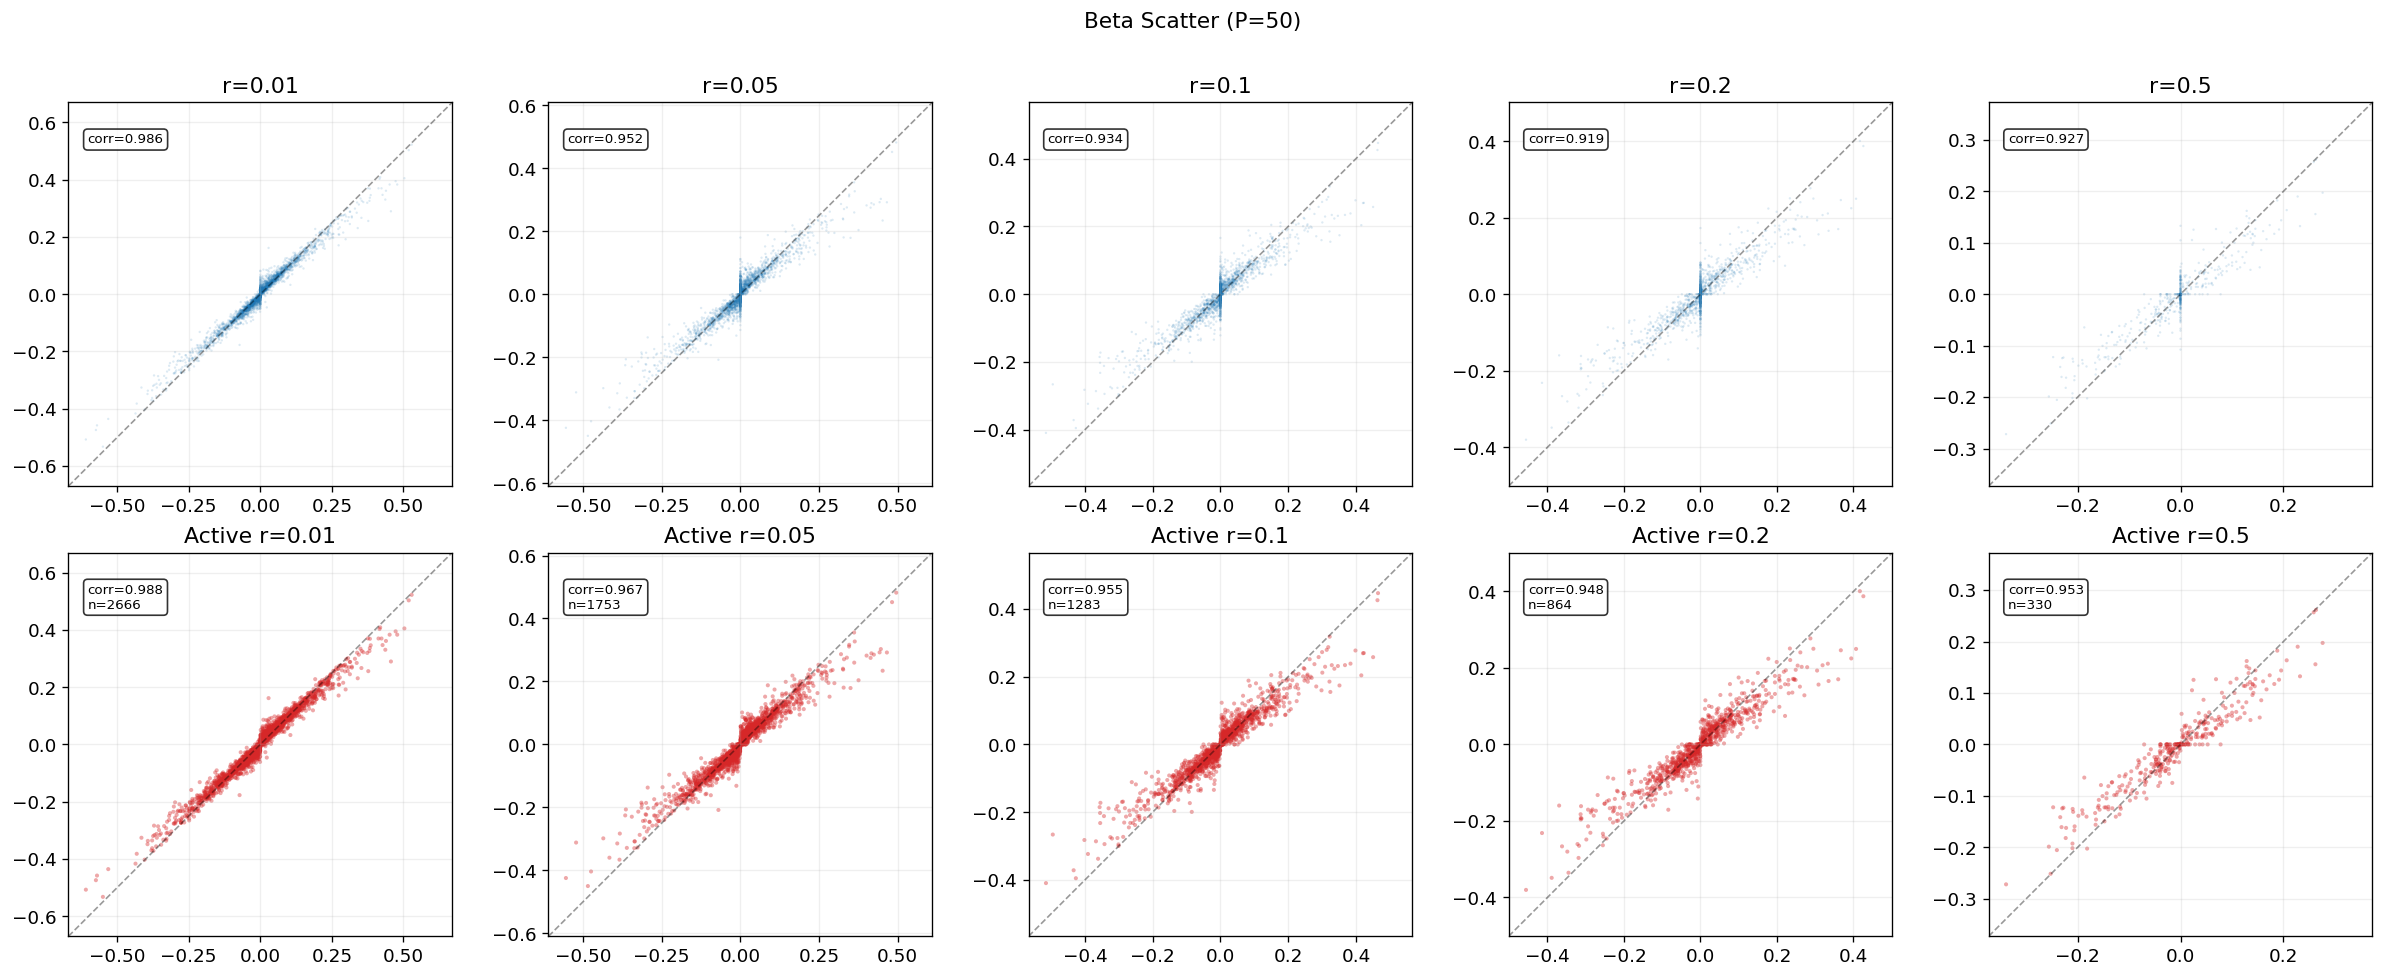

53987

In [16]:
SC_RATIOS = [0.01, 0.05, 0.1, 0.2, 0.5]
N_SC = N_EVAL
model.eval()
with torch.no_grad():
    _, lms = compute_lambda_pair(X_eval[:N_SC], y_eval[:N_SC],
                                  ratio_range=(min(SC_RATIOS), max(SC_RATIOS)))
    with torch.autocast(device_type="cuda", dtype=amp_dtype, enabled=amp_enabled):
        bm_sc = model(X_eval[:N_SC], y_eval[:N_SC],
                       lambdas=lms[:, None] * torch.tensor(SC_RATIOS, device=device)).cpu().numpy()

nr = len(SC_RATIOS)
fig, axes = plt.subplots(2, nr, figsize=(4 * nr, 8))
for col, r in enumerate(SC_RATIOS):
    bm = bm_sc[:, col].flatten()
    # Compute sklearn betas for this ratio if not cached
    if r not in sklearn_betas:
        sk_b = []
        for b in range(N_SC):
            _, coef, _, _ = sklearn_solve(X_np_eval[b], y_np_eval[b], r)
            sk_b.append(coef)
        sklearn_betas[r] = np.stack(sk_b)
    bs = sklearn_betas[r][:N_SC].flatten()
    lim = max(np.abs(bs).max(), np.abs(bm).max(), 0.1) * 1.1

    ax = axes[0, col]
    ax.scatter(bs, bm, alpha=0.15, s=2, c="C0", edgecolors="none")
    ax.plot([-lim, lim], [-lim, lim], "k--", alpha=0.4, lw=1)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
    corr = np.corrcoef(bs, bm)[0, 1] if np.std(bs) > 1e-10 else 0
    ax.text(0.05, 0.92, f"corr={corr:.3f}", transform=ax.transAxes, fontsize=8, va="top",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))
    ax.set_title(f"r={r}"); ax.grid(True, alpha=0.2)

    ax2 = axes[1, col]
    mask = np.abs(bs) > 1e-4
    if mask.sum() > 0:
        ax2.scatter(bs[mask], bm[mask], alpha=0.4, s=6, c="C3", edgecolors="none")
        lnz = max(np.abs(bs[mask]).max(), np.abs(bm[mask]).max(), 0.1) * 1.1
        ax2.plot([-lnz, lnz], [-lnz, lnz], "k--", alpha=0.4, lw=1)
        ax2.set_xlim(-lnz, lnz); ax2.set_ylim(-lnz, lnz)
        c2 = np.corrcoef(bs[mask], bm[mask])[0, 1] if np.std(bs[mask]) > 1e-10 else 0
        ax2.text(0.05, 0.92, f"corr={c2:.3f}\nn={mask.sum()}", transform=ax2.transAxes,
                 fontsize=8, va="top", bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))
    ax2.set_title(f"Active r={r}"); ax2.set_aspect("equal"); ax2.grid(True, alpha=0.2)

fig.suptitle(f"Beta Scatter (P={P})", fontsize=13, y=1.01)
plt.tight_layout(); plt.savefig(FIG_DIR/"05_scatter.png", dpi=150, bbox_inches="tight"); plt.show()
del bm_sc; gc.collect()


## 9. Task × Ratio Heatmaps

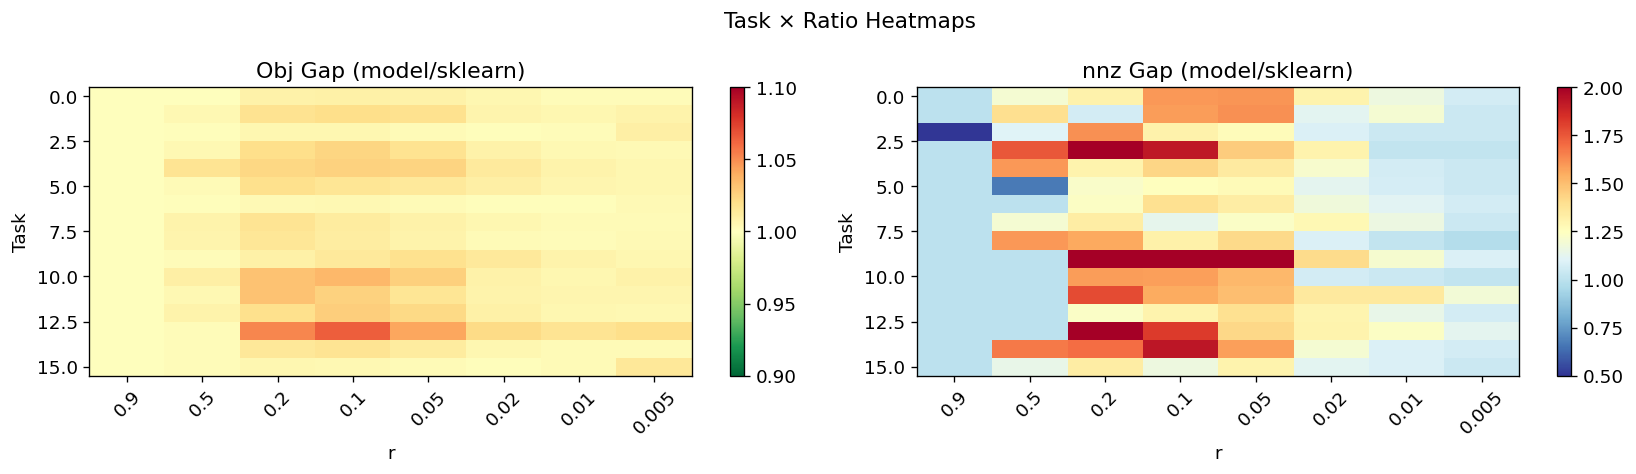

12

In [17]:
N_HM = min(16, N_EVAL)
model.eval()
with torch.no_grad():
    _, lmh = compute_lambda_pair(X_eval[:N_HM], y_eval[:N_HM],
                                  ratio_range=(min(EVAL_RATIOS), max(EVAL_RATIOS)))
    lam_h = lmh[:, None] * torch.tensor(EVAL_RATIOS, device=device)
    with torch.autocast(device_type="cuda", dtype=amp_dtype, enabled=amp_enabled):
        bh = model(X_eval[:N_HM], y_eval[:N_HM], lambdas=lam_h)
    Xc, yc, _, _ = center_xy(X_eval[:N_HM], y_eval[:N_HM])
    oq = lasso_objective_per_query(X_eval[:N_HM], y_eval[:N_HM], bh, lam_h,
                                    precomputed={"Xc": Xc, "yc": yc})

obj_gap = np.zeros((N_HM, len(EVAL_RATIOS)))
nnz_gap = np.zeros_like(obj_gap)
for qi, r in enumerate(EVAL_RATIOS):
    for b in range(N_HM):
        os, cs, _, ns = sklearn_solve(X_np_eval[b], y_np_eval[b], r)
        obj_gap[b, qi] = oq[b, qi].item() / os if os > 0 else float("nan")
        nm = (bh[b, qi].abs() > 1e-4).sum().item()
        nnz_gap[b, qi] = nm / max(ns, 1)

rl = [f"{r:.3g}" for r in EVAL_RATIOS]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
im0 = axes[0].imshow(obj_gap, aspect="auto", cmap="RdYlGn_r", vmin=0.9, vmax=1.1)
axes[0].set_xticks(range(len(rl))); axes[0].set_xticklabels(rl, rotation=45)
axes[0].set_xlabel("r"); axes[0].set_ylabel("Task"); axes[0].set_title("Obj Gap (model/sklearn)")
plt.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(nnz_gap, aspect="auto", cmap="RdYlBu_r", vmin=0.5, vmax=2.0)
axes[1].set_xticks(range(len(rl))); axes[1].set_xticklabels(rl, rotation=45)
axes[1].set_xlabel("r"); axes[1].set_ylabel("Task"); axes[1].set_title("nnz Gap (model/sklearn)")
plt.colorbar(im1, ax=axes[1])

plt.suptitle("Task × Ratio Heatmaps", fontsize=13)
plt.tight_layout(); plt.savefig(FIG_DIR/"06_heatmaps.png", dpi=150, bbox_inches="tight"); plt.show()
del bh, Xc, yc, oq; gc.collect()


## 10. Timing

In [18]:
NL = 50
model.eval()
with torch.no_grad():
    _ = model(X_eval[:1], y_eval[:1], lambdas=torch.tensor([[0.1]], device=device))
    if device.type == "cuda": torch.cuda.synchronize()

    t0 = time.perf_counter()
    pre = model.precompute(X_eval[:1], y_eval[:1]); enc = model.encode_dataset(pre)
    t_enc = time.perf_counter() - t0
    _, lmx = compute_lambda_pair(X_eval[:1], y_eval[:1], ratio_range=(0.5, 0.5))
    lg = lmx[:, None] * torch.logspace(-3, 0, NL, device=device)[None, :]
    t0 = time.perf_counter()
    _ = model.solve_queries(enc, lambdas=lg)
    if device.type == "cuda": torch.cuda.synchronize()
    t_dec = time.perf_counter() - t0
t_m = t_enc + t_dec

Xt, yt = X_np_eval[0], y_np_eval[0]
Xc_ = Xt - Xt.mean(0, keepdims=True); yc_ = yt - yt.mean()
lm_ = np.abs(Xc_.T @ yc_ / N).max()
t0 = time.perf_counter()
for r in np.logspace(-3, 0, NL):
    Lasso(alpha=r * lm_, fit_intercept=True, max_iter=20000, tol=1e-6).fit(Xt, yt)
t_sk = time.perf_counter() - t0

print(f"{'='*55}")
print(f"Timing: 1 task, N={N}, P={P}, {NL} lambdas")
print(f"{'='*55}")
print(f"  sklearn: {t_sk:.3f}s  ({t_sk/NL*1000:.1f}ms/lam)")
print(f"  Krylov:  {t_m:.4f}s  (enc {t_enc*1000:.1f}ms + dec {t_dec*1000:.1f}ms)")
print(f"  Speedup: {t_sk/t_m:.1f}x")
print(f"{'='*55}")


Timing: 1 task, N=500, P=50, 50 lambdas
  sklearn: 0.024s  (0.5ms/lam)
  Krylov:  0.0041s  (enc 3.0ms + dec 1.1ms)
  Speedup: 5.9x


## 11. Summary

In [19]:
print("=" * 65)
print(f"P={P} EXPERIMENT SUMMARY (pregenerated data)")
print("=" * 65)
print(f"\nModel: {n_params:,} params (P-agnostic)")
print(f"Data: {SHARD_DIR.name}")
print(f"\nFrozen paired eval (definitive, identical data):")
print(paired[["obj_gap", "beta_corr", "nnz_model", "nnz_sklearn"]].to_string())
print(f"\nAvg obj gap:   {paired['obj_gap'].mean():.4f}x")
print(f"Avg beta corr: {paired['beta_corr'].mean():.4f}")
print(f"\nTiming ({NL}-lam path): sklearn {t_sk:.3f}s | Krylov {t_m:.4f}s | {t_sk/t_m:.1f}x faster")
print(f"\n{'='*65}")


P=50 EXPERIMENT SUMMARY (pregenerated data)

Model: 87,976 params (P-agnostic)
Data: fix_n500_p50_linear_only

Frozen paired eval (definitive, identical data):
        obj_gap  beta_corr  nnz_model  nnz_sklearn
r                                                 
0.9000   1.0002     0.9689     1.5469       1.4688
0.5000   1.0057     0.9302     6.7500       5.1562
0.2000   1.0170     0.9196    20.0312      13.5000
0.1000   1.0183     0.9358    30.5469      20.0469
0.0500   1.0140     0.9529    38.6719      27.3906
0.0200   1.0067     0.9753    45.1875      36.5000
0.0100   1.0041     0.9865    47.6406      41.6562
0.0050   1.0054     0.9893    48.5781      45.3750

Avg obj gap:   1.0089x
Avg beta corr: 0.9573

Timing (50-lam path): sklearn 0.024s | Krylov 0.0041s | 5.9x faster

